In [1]:
cd /home/sebastin/projects/OCD_Symphony/

/home/sebastin/projects/OCD_Symphony


In [2]:
import argparse
import importlib
import os
import numpy as np
import pandas as pd
import scipy
import scipy.stats
import torch
import seaborn as sbn
import sklearn
from matplotlib import pyplot as plt
from time import time

import OCD_symphony
import OCD_symphony.data_preparation
from OCD_symphony.utils import proj_dir, today

import warnings
warnings.filterwarnings("ignore", category=UserWarning)

/home/sebastin/miniconda3/envs/ocd-symphony/lib/python3.9/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


## Loading HCP dataset (set n_subjs for partial loading)

In [ ]:
importlib.reload(OCD_symphony)
importlib.reload(OCD_symphony.data_preparation)
importlib.reload(OCD_symphony.data_preparation.make_hcp_dataset)

# Load HCP dataset and demographics
t0 = time()
dataset, subjs = OCD_symphony.data_preparation.make_hcp_dataset.make_hcp_dataset_from_pt(path=os.path.join(proj_dir, 'data/hcp'), n_subjs=1000)
hcp_age, hcp_gender = OCD_symphony.data_preparation.make_hcp_dataset.load_hcp_age_gender(subjs)
print(f"Lazy Loading of dataset done in {time()-t0:.1f}s, i.e. {(time()-t0)/60:.1f} minutes.")

/home/sebastin/miniconda3/envs/ocd-symphony/lib/python3.9/site-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()
/home/sebastin/miniconda3/envs/ocd-symphony/lib/python3.9/site-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


## Run inference

In [ ]:
n_samples = len(subjs)
output_file = os.path.join("/home/sebastin/tmp", "memmap_brain_symphony_inference_HCP_tmp.npz")

In [39]:
import OCD_symphony.model.run_inference
importlib.reload(OCD_symphony.model.model_components)
importlib.reload(OCD_symphony.model.run_inference)

t1 = time()
results = OCD_symphony.model.run_inference.run_inference(dataset, output_file, n_samples)
print(f"Inference took {time()-t1:.1f}s, i.e. {(time()-t1)/60:.1f} minutes.")

Inference took 514.9s, i.e. 8.6 minutes.


## Reconstruction accuracy

/home/sebastin/miniconda3/envs/ocd-symphony/lib/python3.9/site-packages/numpy/lib/function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/home/sebastin/miniconda3/envs/ocd-symphony/lib/python3.9/site-packages/numpy/lib/function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


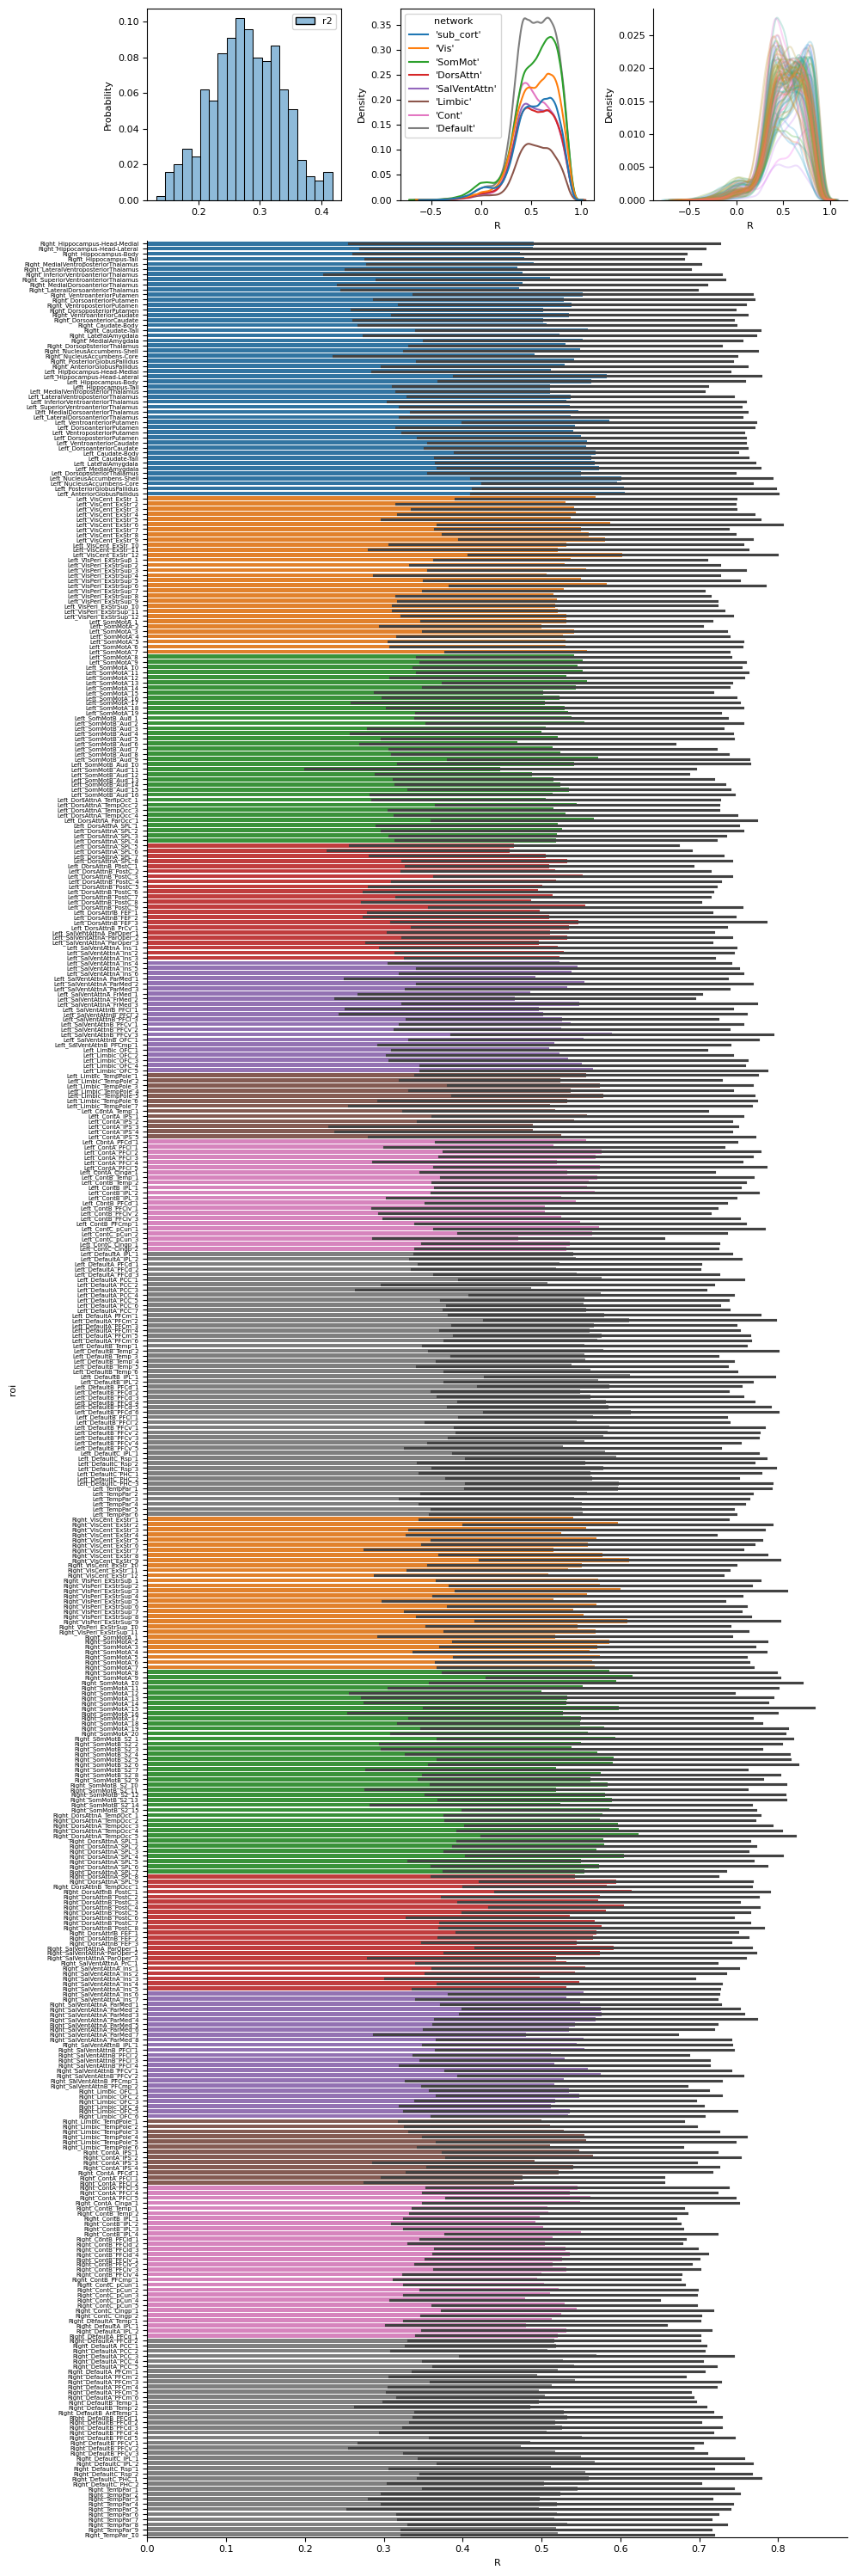

In [34]:
importlib.reload(OCD_symphony.utils.util)
importlib.reload(OCD_symphony.utils)
importlib.reload(OCD_symphony)
importlib.reload(OCD_symphony.model.run_inference)
importlib.reload(OCD_symphony.data_validation.validate_preprocessing)


original_fmri_data = OCD_symphony.model.run_inference.load_HCP_fmri_data(dataset)
#r2_score = OCD_symphony.data_validation.validate_preprocessing.compute_r2(original_fmri_data, results['all_recon_percv'])
OCD_symphony.data_validation.validate_preprocessing.plot_recon_histogram(original_fmri_data, results['all_recon_percv'], subjs)

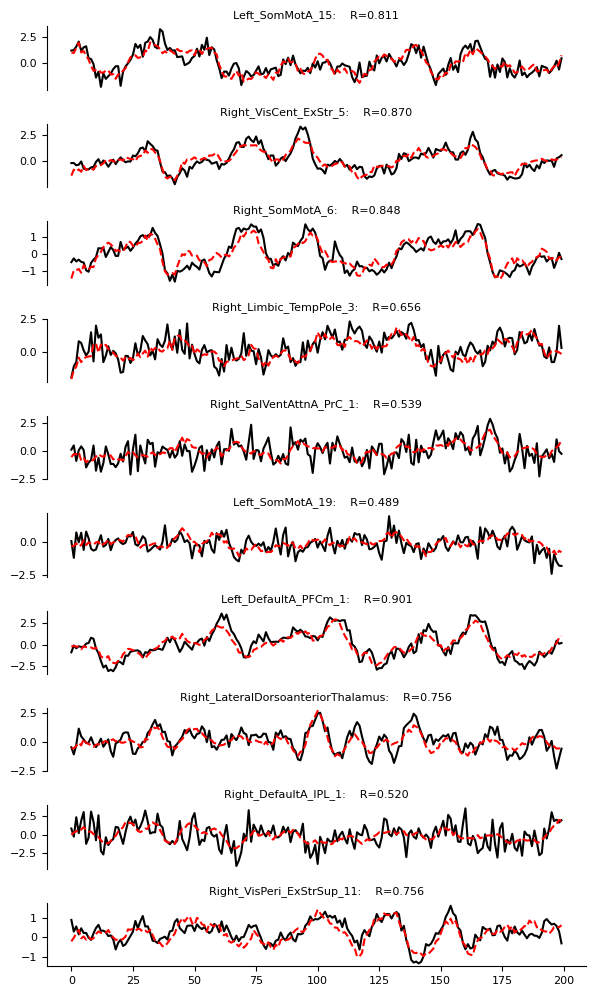

In [35]:
importlib.reload(OCD_symphony.data_validation.validate_preprocessing)
OCD_symphony.data_validation.validate_preprocessing.plot_recon_timeseries(original_fmri_data, results['all_recon_percv'])

## Classification results

### Logistic Regression on latents

In [40]:
importlib.reload(OCD_symphony.predictive_analysis.crossval_preproc)
t2 = time()
OCD_symphony.predictive_analysis.crossval_preproc.perform_classification_with_mean(inputs=results['all_roi_embeddings'],
                                                       subjs=subjs,
                                                       labels=np.array([0 if 'M' in gender else 1 for gender in hcp_gender]) )
print(f"Classification took {time()-t2:.1f}s, i.e. {(time()-t2)/60:.1f} minutes.")

Fitting 3 folds for each of 25 candidates, totalling 75 fits
Best params: {'clf__C': 0.1, 'clf__l1_ratio': 0.1}
Training accuracy 	 = 	 0.550 ± 0.006
Test accuracy 		 = 	 0.548 ± 0.019
Classification took 171.6s, i.e. 2.9 minutes.


In [29]:
importlib.reload(OCD_symphony.predictive_analysis.crossval_preproc)
OCD_symphony.predictive_analysis.crossval_preproc.perform_classification_with_PCA(inputs=results['all_perceiver_attn'],
                                                       subjs=subjs,
                                                       labels=np.array([0 if 'M' in gender else 1 for gender in hcp_gender]) )

--- SPLIT 1 ---
Compute T-stat from training set...


/home/sebastin/miniconda3/envs/ocd-symphony/lib/python3.9/site-packages/scipy/stats/_axis_nan_policy.py:551: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, axis=axis, **kwds)


Perform dimensionality reduction on training set...


ValueError: Input X contains NaN.
PCA does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

# Finetuning on HCP-YA for gender classification

## test the dataset/dataloader for training

In [9]:
%run src/OCD_symphony/data_preparation/make_hcp_dataset.py

AttributeError: module '__main__' has no attribute '__spec__'

## Create train and test sets dataset

In [7]:
importlib.reload(OCD_symphony)
importlib.reload(OCD_symphony.data_preparation)
importlib.reload(OCD_symphony.data_preparation.make_hcp_dataset)

label_name = 'gender'
n_jobs = 16
# Load HCP dataset and demographics
t0 = time()

# train and test sets
trainset, train_subjs = OCD_symphony.data_preparation.make_hcp_dataset.make_hcp_dataset_from_pt(
    path=os.path.join(proj_dir, 'data/hcp'), label=label_name, n_subjs=50, n_jobs=n_jobs
)
testset, test_subjs = OCD_symphony.data_preparation.make_hcp_dataset.make_hcp_dataset_from_pt(
    path=os.path.join(proj_dir, 'data/hcp'), label=label_name, n_subjs=5, start_idx=50, n_jobs=n_jobs
)

print(f"Lazy Loading of dataset done in {time()-t0:.1f}s, i.e. {(time()-t0)/60:.1f} minutes.")

/home/sebastin/miniconda3/envs/ocd-symphony/lib/python3.9/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
/home/sebastin/miniconda3/envs/ocd-symphony/lib/python3.9/site-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()
/home/sebastin/miniconda3/envs/ocd-symphony/lib/python3.9/site-packages/requests/__init__.py:86: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(
/home/sebastin/miniconda3/envs/ocd-symphony/lib/python3.9/site-packages/torch/_utils.py:776: UserWarning: TypedSto

Lazy Loading of dataset done in 65.3s, i.e. 1.1 minutes.


## Run finetuning

In [5]:
import OCD_symphony.model.finetuning
importlib.reload(OCD_symphony.model.finetuning)

args = argparse.Namespace()
args.batch_size = 12
args.n_epochs = 3
args.learning_rate = 1e-4
args.use_wandb = False

t1 = time()
results = OCD_symphony.model.finetuning.finetune(trainset, testset, args)
print(f"Finetuning took {time()-t1:.1f}s, i.e. {(time()-t1)/60:.1f} minutes, i.e. {(time()-t1)/60/60:.1f} hours, i.e. {(time()-t1)/60/60/24:.2f} days.")

2026-06-12 02:52:17.590055: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-06-12 02:52:18.260344: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer.so.7'; dlerror: libnvinfer.so.7: cannot open shared object file: No such file or directory
2026-06-12 02:52:18.260472: W tensorflow/compiler/xla/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libnvinfer_plugin.so.7'; dlerror: libnvinfer_plugin.so.7: cannot open shared object file: No such file or directory
2026-06-12 02:52:18.260484: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Cannot dlopen some TensorRT libraries. If you would like t

[Epoch 1] Train Loss: 228.2347 | Acc: 0.5128 | F1: 0.4322
[Epoch 1] Val Acc: 0.2000 | Val F1: 0.1667
[Epoch 2] Train Loss: 202.8102 | Acc: 0.5842 | F1: 0.5838
[Epoch 2] Val Acc: 0.2083 | Val F1: 0.1781
[Epoch 3] Train Loss: 177.2110 | Acc: 0.7321 | F1: 0.7320
[Epoch 3] Val Acc: 0.5750 | Val F1: 0.3985
✅ Fine-tuning Complete.
Finetuning took 184.5s, i.e. 3.1 minutes, i.e. 0.1 hours, i.e. 0.00 days.
